## Gradual contingency degradation and habit expression

#### Run simulations

just finished sim 0
just finished sim 250
just finished sim 500
just finished sim 750
just finished sim 1000


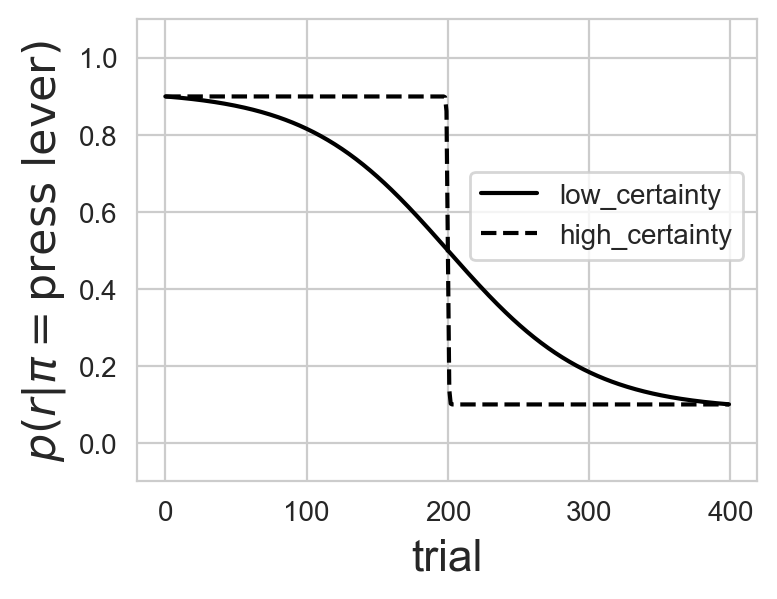

In [1]:
"""Run Some Simulations"""
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.special as scp
from itertools import product
import matplotlib.ticker as ticker
from matplotlib.ticker import MultipleLocator
from scipy.optimize import curve_fit
from classes import Agent, MultiArmedBandit, World
from utilities import create_long_df_gradual_change, plot_reward_regime, run_simulation

sns.set_style("whitegrid")
dpi = 200

#############################################
# setup simulation run, agent, env parameters
############################################


np.random.seed(1)

pars = {}
pars["hs"] = np.array([1000, 10, 1])
h_order = {h: label for h, label in zip(pars["hs"], ["no habit", "moderate habit", "strong habit"])}
pars["k_range"] = [0.02, 3.]
env_order = {k: label for k, label in zip(pars["k_range"], ["low certainty", "high certainty"])}
pars["utility"] = np.array([0.025, 0.95, 0.025])
pars["context_volatility"] = 0.99
pars["changing_rewards"] = True
pars["changing_utility"] = False
pars["nsims"] = 200
pars["debug"] = False

pars["TAU"] = 400
pars["T"] = 2
pars["na"] = 2
pars["ns"] = pars["na"] + 1
pars["no"] = pars["ns"]
pars["nr"] = 3
pars["nc"] = 2
pars["npi"] = pars["na"]**(pars["T"]-1)
pars["train_trials"] = 0
pars["switch"] = pars["TAU"]//2
pars["training_protocol"] = [np.array([0]*(pars["switch"]+pars["train_trials"]) + [1]*pars["switch"])]

# # create gradually changing reward schedule with decay rates k in k_range
start = 0.9
stop = 0.1
logistic = lambda x, k: stop - (start-stop) / (np.exp(pars["switch"]*k) - 1) \
                        + (np.exp(pars["switch"]*k) + 1) / (np.exp(pars["switch"]*k) - 1) \
                        * (start-stop)/(1+np.exp(k*(x-pars["switch"])))

reward_schedules = []
for k in pars["k_range"]:
    x = np.arange(0, pars["switch"]*2, 1)
    p_win = logistic(x, k)
    Rho = np.zeros([pars["nr"], pars["ns"], pars["TAU"]])
    Rho[:, :, pars["train_trials"]:] = np.array([
        [1-p_win, p_win, np.zeros(pars["TAU"])],
        [p_win, 1-p_win, np.zeros(pars["TAU"])],
        [np.zeros(pars["TAU"]), np.zeros(pars["TAU"]), np.ones(pars["TAU"])],
    ])
    Rho[:, :, :pars["train_trials"]] = Rho[:, :, pars["train_trials"]][:, :, None]
    reward_schedules.append((Rho, k))
plot_reward_regime(pars["k_range"], pars["switch"], pars["TAU"], start, stop, dpi=dpi)
plt.ylabel(r"$p(r|\pi=\text{press lever})$", fontsize=16)

################################################
# create pars dictionary for each simulation run
################################################

agent_instance = np.arange(pars["nsims"])
context_volatilities = np.array([pars["context_volatility"]])
parameter_combinations = product(agent_instance, pars["hs"], pars["training_protocol"], context_volatilities, reward_schedules)

sim_params = []
for pi, p in enumerate(parameter_combinations):
    par = pars.copy()
    par["rep"] = p[0]
    par["h"] = p[1]
    par["training_protocol"] = p[2]
    par["context_volatility"] = p[3]
    par["Rho"] = p[4][0]
    par["decay_rate"] = p[4][1]
    par["sim"] = pi
    sim_params.append(par)
    
##################################
# RUN ALL SIMULATIONS
##################################
long_dfs = []
for pi, par in enumerate(sim_params):
    print(f"just finished sim {par['sim']}") if pi % 250 == 0 else None
    world, _, _ = run_simulation(**par)
    long_dfs.append(create_long_df_gradual_change(world, par, env_order, h_order))

env_order = [item for key, item in env_order.items()] 
h_order = [item for key, item in h_order.items()]

long_df = pd.concat(long_dfs)
long_df = long_df.astype({
    "action": "category",
    "habitual_tendency": "category",
    "reward_decay_rate": "category",
    "h": pd.CategoricalDtype(categories=h_order, ordered=True),
    "environment_type": pd.CategoricalDtype(categories=env_order, ordered=True),
})
name = f"data_degradation_{pars['TAU']}_util{pars['utility'][1]}_context{pars['context_volatility']}"
long_df.to_csv(name + "_long.csv", index=False)

### Posterior plots

C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32276\4124508115.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32276\4124508115.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)


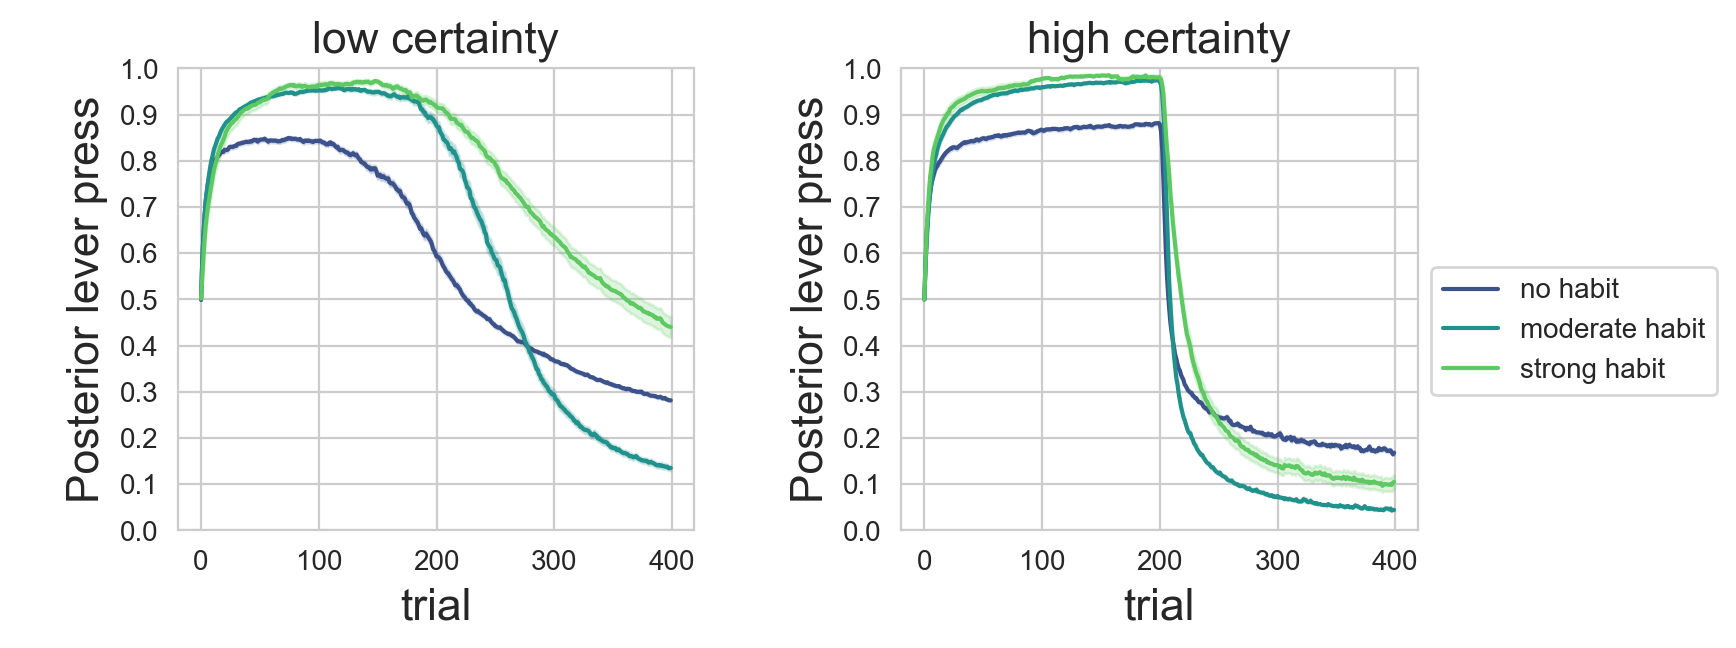

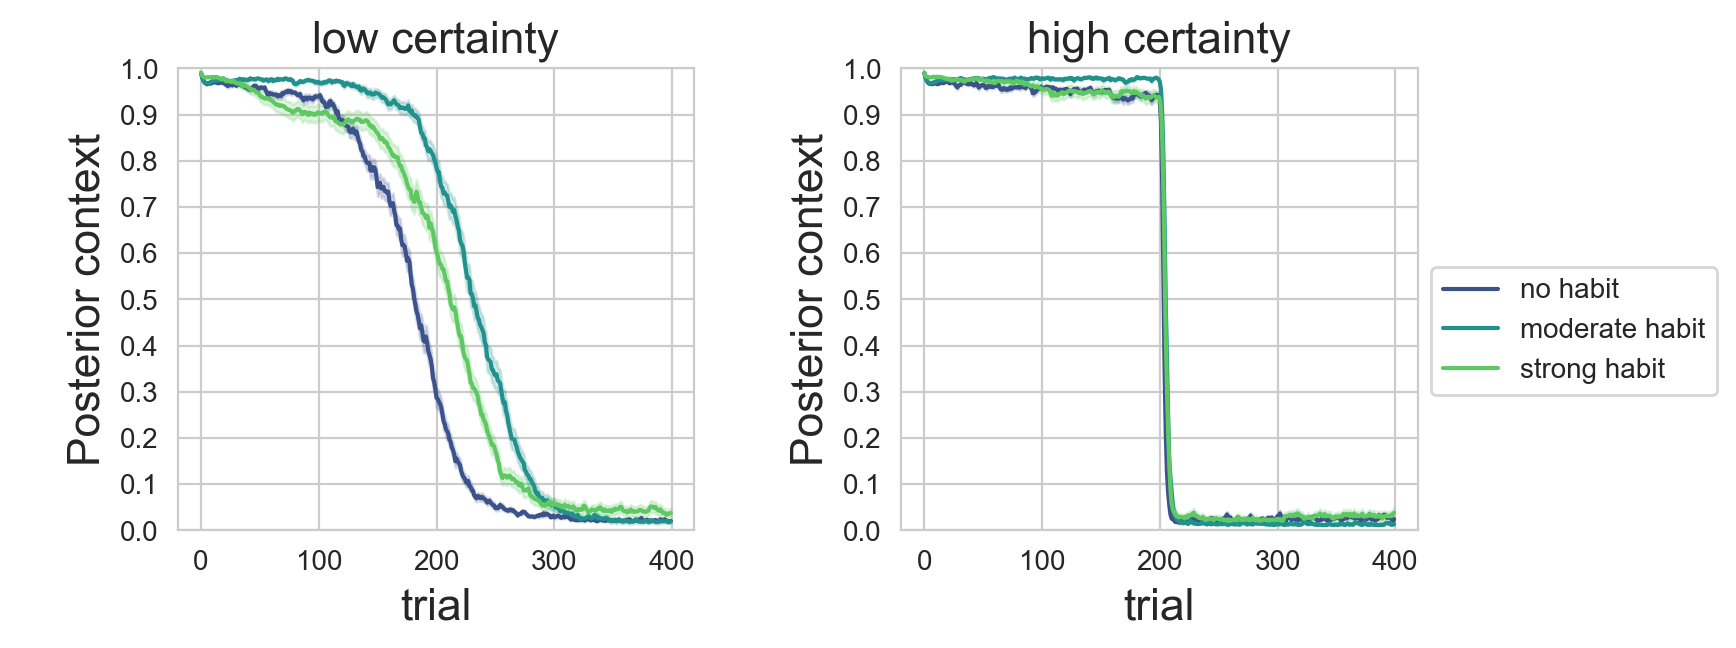

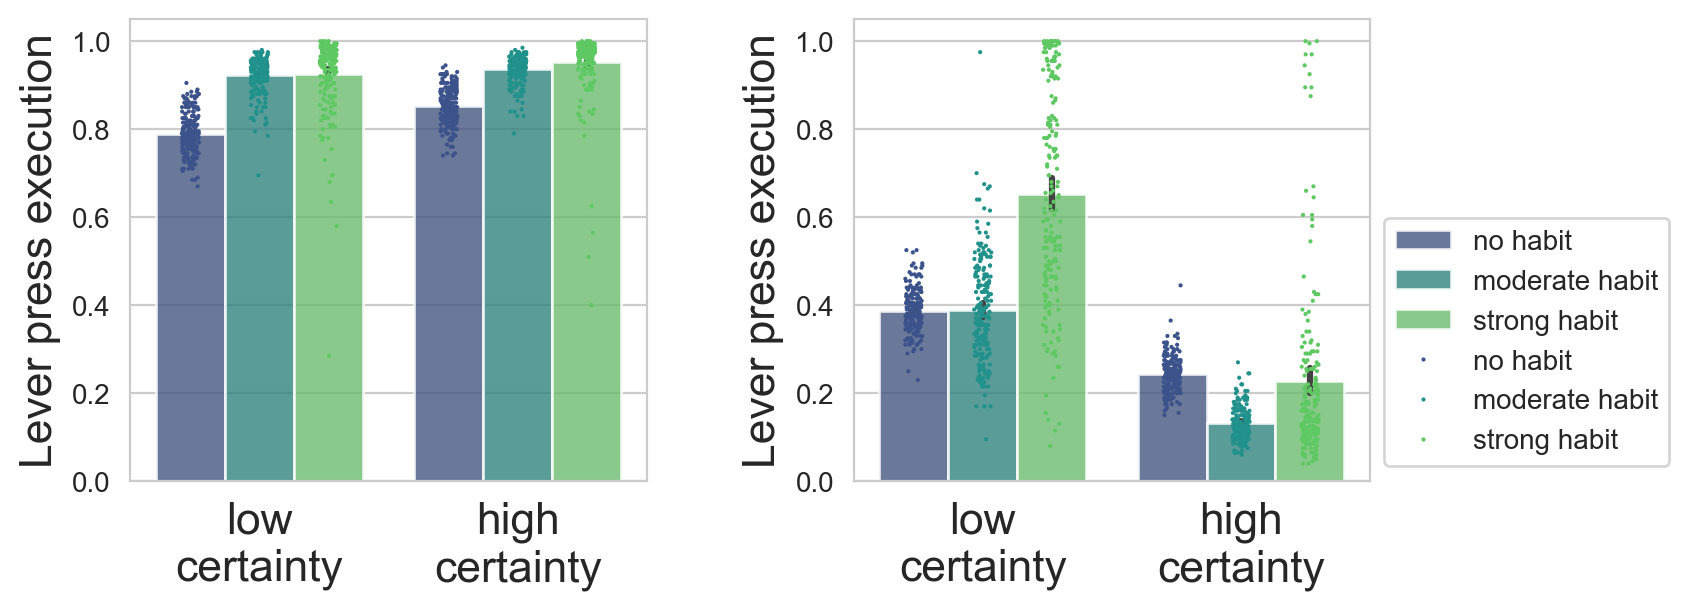

In [2]:
df_long = pd.read_csv("data_degradation_400_util0.95_context0.99_long.csv")
K = len(env_order)
plot_df = df_long.set_index(["h","environment_type","run","tau","t"])


####################################
# Plot policy posterior
####################################
if True:
	plt.figure(figsize=(8,3),dpi=dpi)
	for ki, k in enumerate(env_order):

		plt.subplot(1,K,ki+1)
		g = sns.lineplot(data=plot_df.loc[:,k,:,:,0].reset_index(), x = "tau", y="posterior_pi0", hue="h", errorbar="se", palette="viridis", hue_order=h_order)
		g.set_ylabel("\nPosterior lever press", fontsize=16)
		g.set_xlabel("trial",fontsize=16)
		g.set_title(env_order[ki], fontsize=16)
		g.set_ylim([0,1])
		g.yaxis.set_major_locator(ticker.MultipleLocator(base=0.1)) 
		if ki == len(env_order)-1:
			g.legend(title=None, bbox_to_anchor=(1,0.6))
		else:
			g.get_legend().remove()	
	plt.subplots_adjust(wspace=0.4)


#####################################
#         Context posterior
#####################################
if True:
	plt.figure(figsize=(8,3),dpi=dpi)
	for ki, k in enumerate(env_order):
		# display(plot_df.loc[:,k,:,:,0].reset_index().head())
		g = plt.subplot(1,K,ki+1)
		# g.vlines(x=200,ymin=0,ymax=1, color="black",alpha=0.8)
		sns.lineplot(data=plot_df.loc[:,k,:,:,0].reset_index(), x = "tau", y="posterior_context_c0", hue="h", errorbar="se", palette="viridis", hue_order=h_order)
		g.set_ylabel("\nPosterior context",fontsize=16)
		g.yaxis.set_major_locator(ticker.MultipleLocator(base=0.1)) 
		g.set_xlabel("trial",fontsize=16)
		g.set_title(env_order[ki], fontsize=16)
		g.set_ylim([0,1])
		if ki == len(env_order)-1:
			g.legend(title=None, bbox_to_anchor=(1,0.6))
		else:
			g.get_legend().remove()	
	plt.subplots_adjust(wspace=0.4)



########################################
# Lever 1 pressing in different contexts
########################################
if True:
	plot_df = df_long.query("t==0").groupby(by=["h","environment_type","run","true_context"])["action"].value_counts(normalize=True, dropna=False)
	plot_df = plot_df.reset_index().query("action==0")

	plt.figure(figsize=(8,3),dpi=dpi)
	for ci, c in enumerate(plot_df.true_context.unique()):
		# display(plot_df.loc[:,k,:,:,0].reset_index().head())
		plt.subplot(1,plot_df.true_context.unique().size,ci+1) 
		g = sns.barplot(data=plot_df.query(f"true_context =={ci}"), x="environment_type", order=env_order, y="proportion", hue="h", hue_order=h_order, palette="viridis", alpha=0.8)
		g = sns.stripplot(data=plot_df.query(f"true_context =={ci}"), x="environment_type", order=env_order, y="proportion", hue="h", hue_order=h_order, palette="viridis", dodge=True, s=1.5)
		g.set_xlabel(None)
		g.set_ylabel("Lever press execution", fontsize=16)
		g.legend(title=None)
		g.set_ylim([0,1.05])
		g.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)

		if ci == len(env_order)-1:
			g.legend(title=None, bbox_to_anchor=(1,0.6))
		else:
			g.get_legend().remove()	
	plt.subplots_adjust(wspace=0.4)



######################################################
# reward gathered pre and post optimal action changing
######################################################
if False:
	plot_df = df_long.query("t==1").groupby(by=["h","environment_type","run","true_context"])["reward"].sum()
	plot_df = plot_df.reset_index().query("true_context == 0")
	plt.figure()
	sns.barplot(data=plot_df, x="environment_type", y="reward", hue="h", hue_order=h_order, order=env_order, palette="viridis")

	plt.figure()
	sns.barplot(data=plot_df, hue="environment_type", y="reward", x="h", hue_order=env_order, order=h_order, palette="tab10")
	# plot_df.head()

### Curve fitting Plots

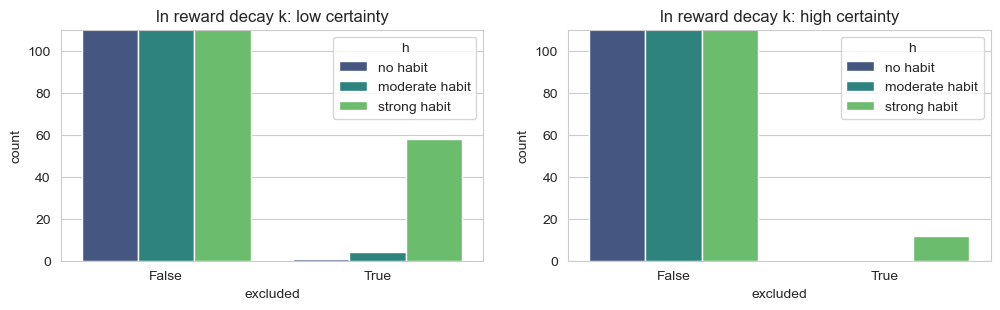

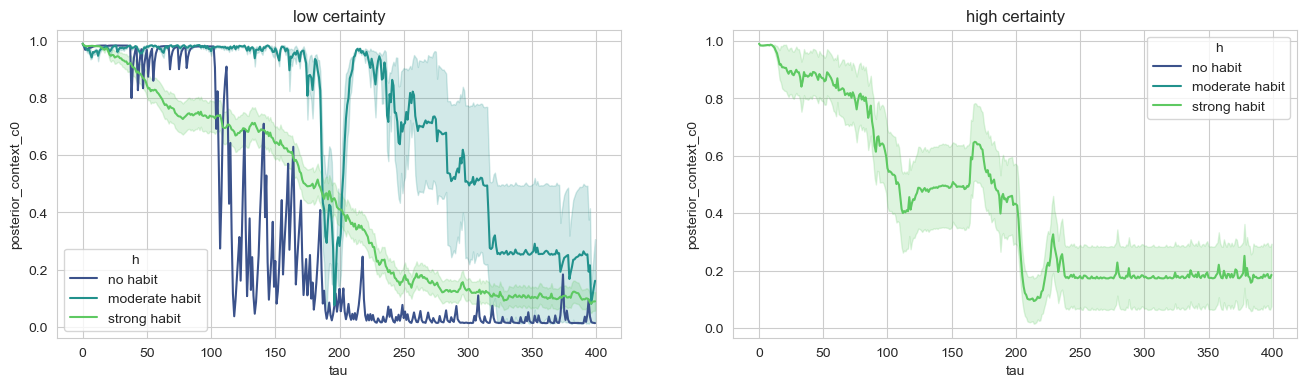

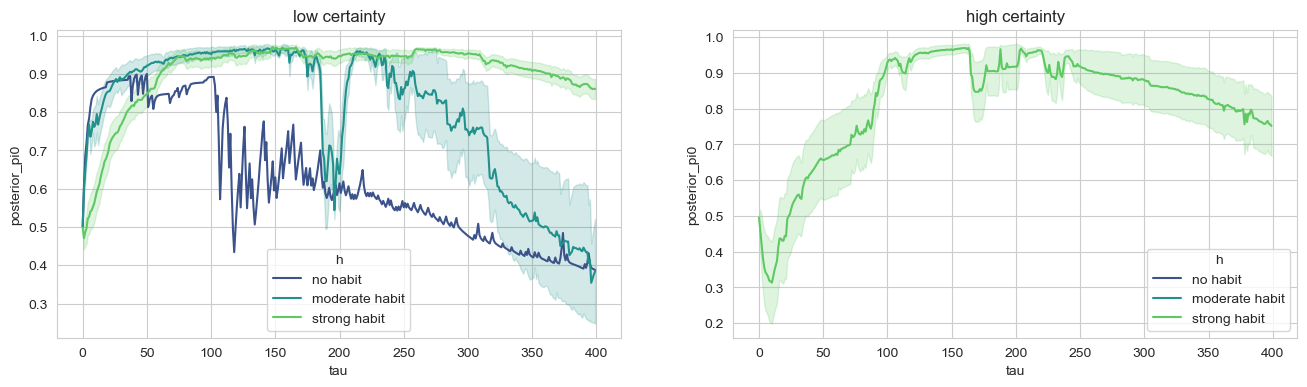

In [3]:
df_long = pd.read_csv("data_degradation_400_util0.95_context0.99_long.csv")

### clean curve fitting results
df_long["excluded"] = False
df_long["exclusion_reason"] = None
TAU = pars["TAU"]

df_long.loc[df_long["policy_a"] < 0.35, ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]   # exclude agents that don't infer second policy with probability higher than 0.35

df_long.loc[df_long["context_a"] < 0.35, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1]  # exclude agents that don't infer second context with probability higher than 0,35

df_long.loc[df_long["context_c"].isna(),  ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1] # exclude all agents where no sigmoid could be fitted at all

df_long.loc[df_long["policy_c"].isna(),  ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1] # exclude all agents where no sigmoid could be fitted at all

df_long.loc[df_long["context_c"] > TAU//2, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1] # 
						   #
df_long.loc[(df_long["policy_c"] > 130) & (df_long["policy_a"] > 0.7) & (df_long["policy_a"] > 1.01), ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]

df_long.loc[df_long["context_c"] < -TAU//4, ["excluded","exclusion_reason", "context_c"]] = [True, "context", (TAU//2)+1]

df_long.loc[df_long["policy_c"] < -TAU//4, ["excluded", "exclusion_reason", "policy_c"]] = [True, "policy", (TAU//2)+1]


###########################################################
#### Show amounts of excluded agents per simulation subgroup
############################################################
df = df_long.query("t == 0 and tau == 0")
K = len(env_order)
fig, axes = plt.subplots(1,K, figsize=(12,3))

for ki, k in enumerate(env_order):
	sns.countplot(ax=axes[ki], data=df.query(f"environment_type == '{k}'"),x="excluded", hue="h", palette="viridis",hue_order=h_order)

	axes[ki].set_title(f"ln reward decay k: {k}")
	axes[ki].set_ylim([0,110])

#######################################################
### Inferred posterior over contexts for excluded agents
########################################################
plot_df = df_long.set_index(["excluded","h","environment_type","run","tau","t"])
plt.figure(figsize=(16,4))
for ki, k in enumerate(env_order):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	plt.subplot(1,K,ki+1)
	ax = sns.lineplot(data=plot_df.loc[True,:,k,:,:,0].reset_index(), x = "tau", y="posterior_context_c0", hue="h", errorbar="se", palette="viridis",hue_order=h_order)
	ax.set_title(k)

########################################################
#### Inferred posterior over policies for excluded agents
#########################################################
plt.figure(figsize=(16,4))
for ki, k in enumerate(env_order):
	# display(plot_df.loc[:,k,:,:,0].reset_index().head())
	plt.subplot(1,K,ki+1)
	ax = sns.lineplot(data=plot_df.loc[True,:,k,:,:,0].reset_index(), x = "tau", y="posterior_pi0", hue="h", errorbar="se", palette="viridis",hue_order=h_order)
	ax.set_title(k)

##################
#### Run refitting
##################
if False:
	df = df_long[df_long["excluded"]]

	grouped = df.groupby(["environment_type", "h", "exclusion_reason"], observed=True)
	for (k,h, exclusion_reason), group in grouped:
		
		# create mask to identify rows to change in df_long
		sims = group.sim.unique()
		print("exclusion reason: ", exclusion_reason)
		mask = df_long["sim"].isin(sims)

		# run fitting on the mean posterior of all excluded agents
		gr = group.set_index(["tau","t"])

		q_action = gr.loc[(slice(None),0), "posterior_pi0"]
		q_action = q_action.groupby(by="tau").mean().to_numpy()

		q_context = gr.loc[(slice(None),1), "posterior_context_c0"]
		q_context = q_context.groupby(by="tau").mean().to_numpy()
		
		context_params, context_pcov, context_func, policy_params, policy_func, se = fit_posterior_traces(q_context, q_action, switch, TAU)

		# change values in df_long
		if exclusion_reason == "policy":		
			cols = ["policy_a", "policy_b", "policy_c", "policy_d", "policy_func"]
			vals = np.array(list(policy_params) + [policy_func])
			vals[np.isnan(vals)] = TAU // 2
			for col, val in zip(cols,vals):
				df_long.loc[mask, col] = val
			print(f"h:{h}, env:{k}, exclusion: {exclusion_reason}, policy_c:{vals[2]}")
		
		if exclusion_reason == "context":
			cols = ["context_a", "context_b", "context_c", "context_d", "context_func"]
			vals = np.array(list(context_params) + [context_func])
			vals[np.isnan(vals)] = TAU // 2
			for col, val in zip(cols,vals):
				df_long.loc[mask, col] = val
			print(f"h:{h}, env:{k}, exclusion: {exclusion_reason}, context_c:{vals[2]}")


		# change values in df_long
		# cols = ["context_a", "context_b", "context_c", "context_d", "context_func", "policy_a", "policy_b", "policy_c", "policy_d", "policy_func"]
		# vals = np.array(list(context_params) + [context_func] + list(policy_params) + [policy_func])
		# vals[np.isnan(vals)] = TAU // 2
		# for col, val in zip(cols,vals):
		# 	df_long.loc[mask, col] = val

		# print(f"h:{h}, env:{k}, context_c:{vals[2]}, policy_c:{vals[7]}")


C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32276\838832737.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
C:\Users\ivsi289a\AppData\Local\Temp\ipykernel_32276\838832737.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)


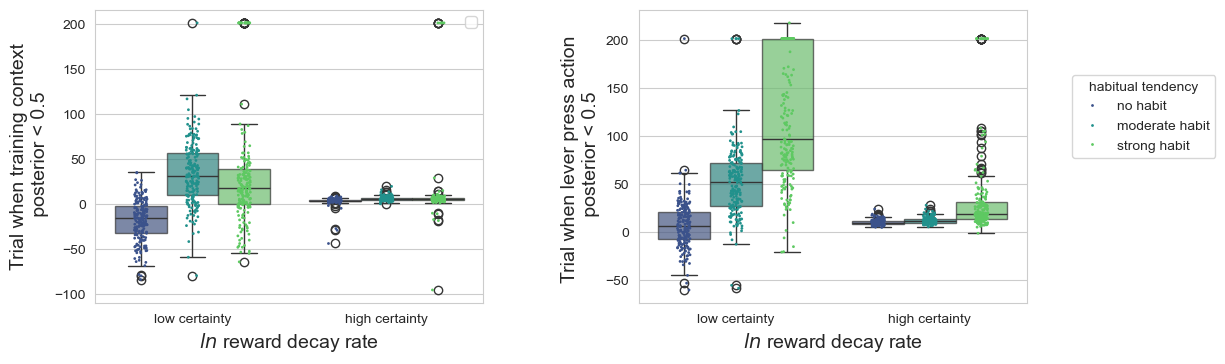

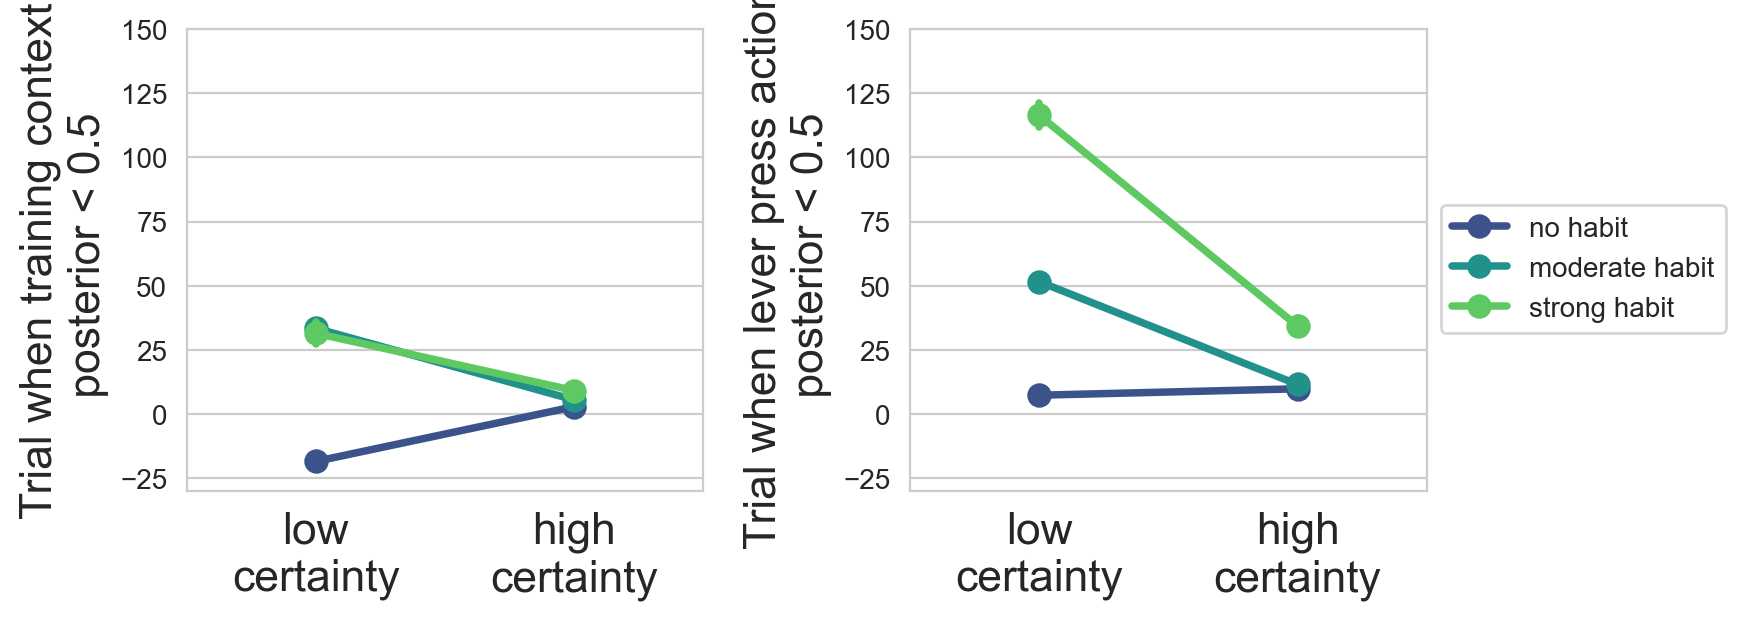

In [4]:
df = df_long.query("t == 0 and tau == 0")

#####################################################
# Trial at which novel context inferred BOXPLOT
####################################################

fig, axes = plt.subplots(1,2, figsize=(10,3.5))
plt.tight_layout()
plt.subplots_adjust(wspace=0.4)
sns.boxplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", boxprops=dict(alpha=.7), palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.stripplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", palette="viridis", dodge=True, s=2,hue_order=h_order, order=env_order)
sns.boxplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", boxprops=dict(alpha=.7), palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.stripplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", palette="viridis", dodge=True, s=2,hue_order=h_order, order=env_order)

axes[0].set_ylabel("Trial when training context\n posterior < 0.5", fontsize=14)
axes[1].set_ylabel("Trial when lever press action \n posterior < 0.5", fontsize=14)

axes[0].legend([])
axes[1].legend(bbox_to_anchor=(1.,0.8), title="habitual tendency")


for ax in axes:
	# ax.set_ylim([-30,150])
	ax.set_xlabel(rf"$ln$ reward decay rate", fontsize=14)
axes[1].legend(bbox_to_anchor=(1.1,0.8), title=r"habitual tendency")


#################################################
# Trial at which novel context inferred POINTPLOT
#################################################

fig, axes = plt.subplots(1,2, figsize=(8,3),dpi=dpi)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.4)
sns.pointplot(ax=axes[0], data=df, x="environment_type", y="context_c", hue="h", marker="o",errorbar="se",palette="viridis",legend=None,hue_order=h_order, order=env_order)
sns.pointplot(ax=axes[1], data=df, x="environment_type", y="policy_c", hue="h", marker="o", errorbar="se",palette="viridis",hue_order=h_order, order=env_order)
axes[0].set_ylabel("Trial when training context\n posterior < 0.5", fontsize=16)
axes[1].set_ylabel("Trial when lever press action \n posterior < 0.5", fontsize=16)

for ax in axes:
	ax.set_ylim([-30,150])
	ax.set_xlabel(None)
	ax.xaxis.set_ticklabels(labels=[label.replace(" ","\n") for label in env_order], fontsize=16)
axes[1].legend(bbox_to_anchor=(1,0.65), title=None)




In the first two plots we look at the distribution of the inferred inflection point parameters for the posterior over contexts and policies (context_c and policy_c). e inflection point parameter corresponds to the trial at which fitted sigmoid becomes more than 50% of its max values. As explained above, cases where sigmoid could not be fitted or fitted nonsense, the inflection point was set to TAU//2. 

Plots:
1. Violin plot of inferred inflection points for the context and policy posteriors. 
2. Same data, but showing the average inflection point for different habit learneres and different rates of reward decay, similar to the plot in Sarah's paper.
3. Plot of how many inflection points were manually set to TAU//2, corresponding to the number of agents, that failed to acquiere correct contextual structure alltogether.

From these plots can see that overall the quicker rewards decay, the faster agents perceive a change in context, as expected. Additionally, more agents manage to learn correct contextual structure and switch action in response to context change. 

Gradual changes in reward instead lead to more within context adaptation and slower shift to learning a novel context (higher policy_c, context_c and more excluded (failed) agents).

Importantly, **this effect is the most pronounced for strong habit learners (those with log habitual_tendency close to 0)** as hypothesized, with strong habit learners having the most failed agents and the highest inflection points. 

Overall **very few habit learners completely fail to infer presence of a new context**. The reward prediction error drives them to eventually notice that something new has happened. Even so, in practice they either 

1. fail to learn an adequate second context (with reward distributions for that context staying close to uniform).
2. infer the presence of a second context, with the correct contingencies (higher reward rate for action 2 than action 1) but are unable to switch response nonetheless, due to habit bleedthrough. From an SUD perspective, the agent is capable of recognizing that it is in a novel situation where the originally learned drug action is no longer rewarding but the compulsion to consume persists even in this new context.

Below are some examples of such behaviour.

